# 📦 Superstore Demand Forecasting — Forecast and Inventory Plan
**Tools:** Python · Pandas · statsmodels · Matplotlib  
**Goal:** Forecast monthly sales for January–June 2018 by category, with confidence intervals, and turn the forecast into inventory recommendations: which categories and months need more stock.

---

| Section | Question it answers |
|---|---|
| 1. Setup | Which model, and which data? |
| 2. Final models | What exactly is refitted? |
| 3. Forecast | How much will each category sell, and how sure are we? |
| 4. Sanity check | Which months look out of line with last year? |
| 5. Inventory plan | How much stock does each category need each month? |
| 6. Recommendations | What should the business do? |

---
## 1. SETUP
> **Goal:** Load all 48 months. The holdout's job (validation) is done, so the final models use every month available, including 2017's growth.

**Model choice** (from notebooks 02 and 03, holdout Jan–Dec 2017):

| Series | Model | Holdout WAPE | Why |
|---|---|---|---|
| Furniture | SARIMA | 19.8% | Most accurate model |
| Office Supplies | SARIMA | 29.3% | Ties with Holt-Winters (29.2%) but with half the bias (−13% vs −26%) and confidence intervals |
| Technology | SARIMA | 32.3% | Most accurate model |
| Total | Sum of the three | 20.5% | More accurate than any direct Total model, and consistent with the category plans |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from src.config import FORECAST_HORIZON, OUTPUTS_DIR, SERVICE_LEVEL
from src.forecasting.inventory import bottom_up_total, safety_stock, stock_target
from src.forecasting.sarima import refit, seasonal_strength, select_sarima
from src.forecasting.series import CATEGORIES, SERIES, TOTAL, load_monthly_sales, split_holdout
from src.plotting import AXIS, INK, INK_SECONDARY, MONTH_LABELS, MUTED, ORDINAL_BLUES, SERIES_COLORS, apply_style, thousands

apply_style()

TABLES_DIR = OUTPUTS_DIR / "forecasting" / "tables"
FIGURES_DIR = OUTPUTS_DIR / "forecasting" / "figures"

sales = load_monthly_sales()
train, _ = split_holdout(sales)
print(f"Fitting on {len(sales)} months ({sales.index.min():%b %Y} → {sales.index.max():%b %Y}); "
      f"forecasting {FORECAST_HORIZON} months; service level {SERVICE_LEVEL:.0%}")

Fitting on 48 months (Jan 2014 → Dec 2017); forecasting 6 months; service level 90%


---
## 2. FINAL MODELS
> **Goal:** Refit the **validated specifications** on all 48 months.

What the holdout validated is each category's specification: its orders, differencing and trend, as chosen on the training months. The final models keep those and only re-estimate the parameters with 2017 included.

Re-running the whole selection on 48 months would produce models the holdout never tested. For Office Supplies it would also change the structure: its seasonal strength drops from 0.65 to 0.61, just under the 0.64 rule, so it would lose its seasonal difference and flatten the seasonal pattern (the table below shows this).

In [2]:
TREND_LABELS = {"n": "none", "c": "constant", "t": "drift"}

def describe(result):
    (p, d, q), (P, D, Q, s) = result.model.order, result.model.seasonal_order
    return f"SARIMA({p},{d},{q})({P},{D},{Q})[{s}]"

specs = {name: select_sarima(train[name])[0] for name in CATEGORIES}
final = {name: refit(specs[name], sales[name]) for name in CATEGORIES}

pd.DataFrame({
    name: {
        "validated model": describe(final[name]),
        "trend": TREND_LABELS[final[name].model.trend],
        "seasonal strength, 36 months": seasonal_strength(train[name]),
        "seasonal strength, 48 months": seasonal_strength(sales[name]),
    }
    for name in CATEGORIES
}).T.style.format({"seasonal strength, 36 months": "{:.2f}", "seasonal strength, 48 months": "{:.2f}"})

,validated model,trend,"seasonal strength, 36 months","seasonal strength, 48 months"
Furniture,"SARIMA(0,0,0)(1,1,0)[12]",drift,0.90,0.84
Office Supplies,"SARIMA(1,0,0)(0,1,1)[12]",drift,0.65,0.61
Technology,"SARIMA(0,1,1)(1,0,0)[12]",drift,0.57,0.56


---
## 3. FORECAST
> **Goal:** Forecast January–June 2018 for each category with 80% and 95% intervals, and build Total as their sum.

### 3.1 — Category Forecasts

In [3]:
forecasts = {name: final[name].get_forecast(FORECAST_HORIZON) for name in CATEGORIES}
means = pd.DataFrame({name: fc.predicted_mean for name, fc in forecasts.items()})
ses = pd.DataFrame({name: fc.se_mean for name, fc in forecasts.items()})
means.index.name = ses.index.name = "month"

### 3.2 — Total as the Sum of the Categories
The three categories' forecast errors are partly correlated: a strong month tends to be strong across categories. The standard error of the total uses the correlation of the models' residuals, so the total's interval is neither too narrow (assuming independence) nor too wide (assuming they always move together).

In [4]:
# Skip the first months, where the models are still initialising their differences
burn_in = max(r.model.order[1] + r.model.seasonal_order[1] * 12 for r in final.values())
residual_corr = pd.DataFrame({name: final[name].resid.iloc[burn_in:] for name in CATEGORIES}).corr()

means[TOTAL], ses[TOTAL] = bottom_up_total(means[CATEGORIES], ses[CATEGORIES], residual_corr)
means, ses = means[SERIES], ses[SERIES]

print(f"Residual correlation between categories ({len(sales) - burn_in} months):")
residual_corr.round(2)

Residual correlation between categories (36 months):


,Furniture,Office Supplies,Technology
Furniture,1.00,0.27,-0.00
Office Supplies,0.27,1.00,0.12
Technology,-0.00,0.12,1.00


### 3.3 — Forecast Table

In [5]:
def interval(level):
    z = norm.ppf(0.5 + level / 2)
    return (means - z * ses).clip(lower=0), means + z * ses

lower_80, upper_80 = interval(0.80)
lower_95, upper_95 = interval(0.95)

forecast_table = pd.concat(
    {"forecast": means, "lower_80": lower_80, "upper_80": upper_80, "lower_95": lower_95, "upper_95": upper_95, "se": ses},
    names=["measure", "series"], axis=1,
).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)[SERIES]
forecast_table.to_csv(TABLES_DIR / "forecast_2018H1.csv")

(forecast_table.xs("forecast", axis=1, level=1) / 1000).round(1).rename(index=lambda m: f"{m:%b %Y}").assign(**{"": "($K)"})

series,Total,Furniture,Office Supplies,Technology,
month,,,,,
Jan 2018,51.0,8.9,18.8,23.2,($K)
Feb 2018,43.9,9.0,15.9,19.0,($K)
Mar 2018,67.7,13.9,23.3,30.5,($K)
Apr 2018,56.4,12.5,21.9,22.0,($K)
May 2018,62.7,19.3,20.7,22.7,($K)
Jun 2018,67.3,20.5,22.5,24.3,($K)


In [6]:
h1 = pd.DataFrame({
    "H1 2017 actual": sales.loc["2017-01":"2017-06", SERIES].sum(),
    "H1 2018 forecast": means.sum(),
})
h1["growth"] = h1["H1 2018 forecast"] / h1["H1 2017 actual"] - 1
h1["full-year 2017 growth"] = sales.loc["2017", SERIES].sum() / sales.loc["2016", SERIES].sum() - 1
h1.style.format({"H1 2017 actual": "${:,.0f}", "H1 2018 forecast": "${:,.0f}", "growth": "{:+.0%}", "full-year 2017 growth": "{:+.0%}"})

,H1 2017 actual,H1 2018 forecast,growth,full-year 2017 growth
Total,"$256,909","$349,063",+36%,+20%
Furniture,"$68,756","$84,114",+22%,+8%
Office Supplies,"$88,954","$123,166",+38%,+34%
Technology,"$99,200","$141,783",+43%,+20%


### 3.4 — Forecast Chart

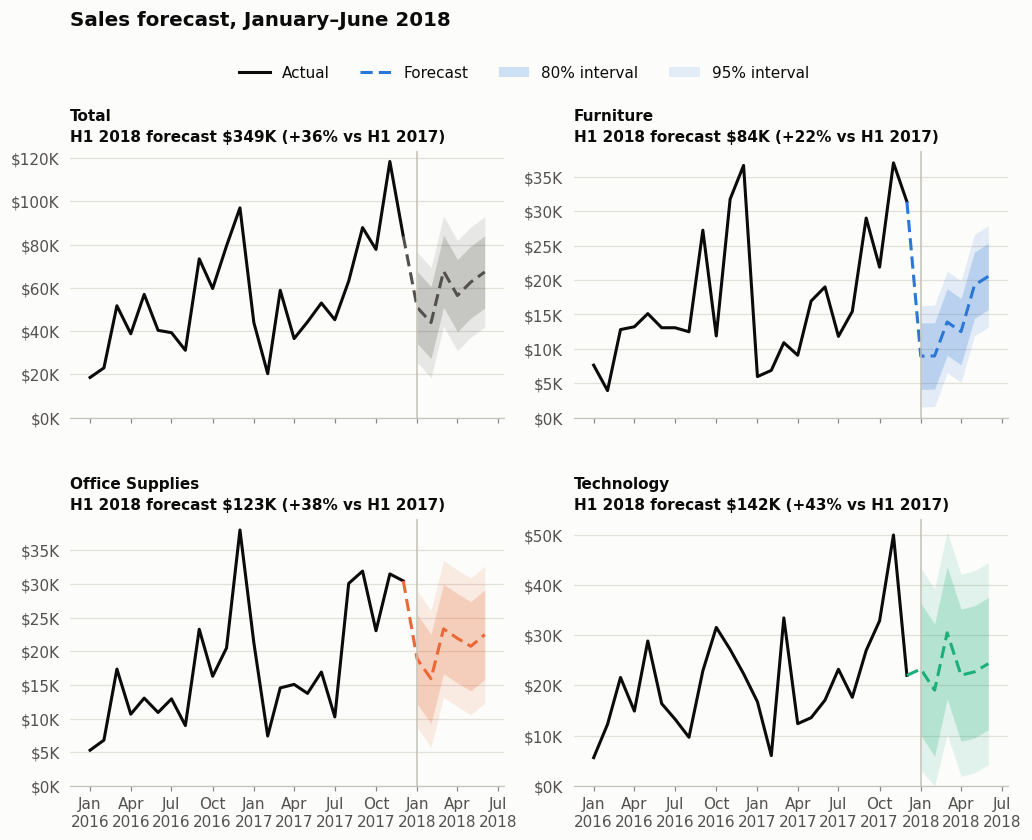

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, gridspec_kw={"hspace": 0.38, "wspace": 0.16})
history = sales.loc["2016":]
# Connect the forecast line to the last actual month
joined = lambda last, values: pd.concat([last, values])

for ax, name in zip(axes.flat, SERIES):
    color = SERIES_COLORS[name]
    ax.fill_between(means.index, lower_95[name], upper_95[name], color=color, alpha=0.12, linewidth=0, label="95% interval")
    ax.fill_between(means.index, lower_80[name], upper_80[name], color=color, alpha=0.22, linewidth=0, label="80% interval")
    ax.plot(history.index, history[name], color=INK, label="Actual")
    ax.plot(joined(history[name].iloc[-1:], means[name]).index, joined(history[name].iloc[-1:], means[name]).values,
            color=color, linestyle=(0, (4, 2)), label="Forecast")
    ax.axvline(means.index[0], color=AXIS, linewidth=1)
    ax.set_title(f"{name}\nH1 2018 forecast ${means[name].sum() / 1000:,.0f}K ({h1.loc[name, 'growth']:+.0%} vs H1 2017)",
                 fontsize=10, linespacing=1.5)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(thousands)

for ax in axes[-1]:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))

handles, labels = axes[0, 1].get_legend_handles_labels()
order = [2, 3, 1, 0]
fig.legend([handles[i] for i in order], [labels[i] for i in order], loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=4)
fig.suptitle("Sales forecast, January–June 2018", x=0.125, ha="left", fontsize=13, fontweight="bold", y=1.05)
fig.savefig(FIGURES_DIR / "08_forecast_2018H1.png")
plt.show()

---
## 4. SANITY CHECK AGAINST LAST YEAR
> **Goal:** Flag forecast months that are far out of line with a simple reference, so a planner reviews them before ordering.

The reference is the same month of 2017 grown by the category's full-year 2017 growth rate. A forecast more than 50% away from it is flagged. This is not another model: it catches months where SARIMA's known weaknesses could mislead the plan. In the holdout, for example, SARIMA forecast Technology's February at \$19.7K against \$6.0K actual, because it does not fully capture the January–February trough.

In [8]:
FLAG_THRESHOLD = 0.50

last_year = sales.loc["2017-01":"2017-06", SERIES].set_axis(means.index)
reference = last_year * (1 + h1["full-year 2017 growth"])
gap = means / reference - 1
flags = gap.abs() > FLAG_THRESHOLD

check = pd.concat({"forecast": means, "reference": reference, "gap": gap}, axis=1)
print("Months flagged for review (forecast vs last year grown by 2017 growth):")
for name in CATEGORIES:
    for month in flags.index[flags[name]]:
        print(f"  {name:<16} {month:%b %Y}: forecast ${means.loc[month, name]:,.0f}  vs reference ${reference.loc[month, name]:,.0f}  ({gap.loc[month, name]:+.0%})")

(gap[CATEGORIES] * 100).round(0).rename(index=lambda m: f"{m:%b}").T.assign(**{"": "(% gap)"})

Months flagged for review (forecast vs last year grown by 2017 growth):
  Office Supplies  Feb 2018: forecast $15,918  vs reference $9,911  (+61%)
  Technology       Feb 2018: forecast $19,045  vs reference $7,235  (+163%)


month,Jan,Feb,Mar,Apr,May,Jun,
Furniture,38.0,21.0,18.0,27.0,5.0,-0.0,(% gap)
Office Supplies,-34.0,61.0,20.0,9.0,13.0,-1.0,(% gap)
Technology,16.0,163.0,-24.0,48.0,39.0,19.0,(% gap)


---
## 5. INVENTORY PLAN
> **Goal:** Convert each month's forecast into a stock target.

- **Forecast:** expected sales. Stocking exactly this runs short in about half of the months.
- **Stock target:** the sales level stock should cover to run short in only 1 month in 10: the {SERVICE_LEVEL:.0%} service level, set in `src/config.py`. It equals the forecast plus a **safety stock** of 1.28 standard errors.
- **Values are in sales dollars**, the unit the forecasts are in. Converting to units needs the product mix and prices, which vary widely within a category.
- **Lead time:** stock has to be ordered before the month it covers. A target for March is an order placed in January or February, depending on the supplier.

In [9]:
plan = pd.concat({
    "forecast": means[CATEGORIES],
    "safety_stock": safety_stock(ses[CATEGORIES], SERVICE_LEVEL),
    "stock_target": stock_target(means[CATEGORIES], ses[CATEGORIES], SERVICE_LEVEL),
    "same_month_2017": last_year[CATEGORIES],
}, names=["measure", "category"], axis=1).stack(level="category", future_stack=True).reset_index()
plan["forecast_vs_same_month_2017"] = plan["forecast"] / plan["same_month_2017"] - 1
plan["safety_share"] = plan["safety_stock"] / plan["stock_target"]
plan["review"] = [flags.loc[m, c] for m, c in zip(plan["month"], plan["category"])]
plan.to_csv(TABLES_DIR / "inventory_plan_2018H1.csv", index=False)

plan.assign(month=plan["month"].dt.strftime("%b %Y")).style.format({
    "forecast": "${:,.0f}", "safety_stock": "${:,.0f}", "stock_target": "${:,.0f}", "same_month_2017": "${:,.0f}",
    "forecast_vs_same_month_2017": "{:+.0%}", "safety_share": "{:.0%}",
}).hide(axis="index")

month,category,forecast,safety_stock,stock_target,same_month_2017,forecast_vs_same_month_2017,safety_share,review
Jan 2018,Furniture,"$8,929","$4,827","$13,756","$5,964",+50%,35%,False
Jan 2018,Office Supplies,"$18,816","$6,618","$25,434","$21,274",-12%,26%,False
Jan 2018,Technology,"$23,248","$13,147","$36,395","$16,733",+39%,36%,False
Feb 2018,Furniture,"$8,968","$4,827","$13,794","$6,866",+31%,35%,False
Feb 2018,Office Supplies,"$15,918","$6,637","$22,555","$7,408",+115%,29%,True
Feb 2018,Technology,"$19,045","$13,148","$32,193","$6,027",+216%,41%,True
Mar 2018,Furniture,"$13,905","$4,827","$18,732","$10,893",+28%,26%,False
Mar 2018,Office Supplies,"$23,316","$6,638","$29,953","$14,550",+60%,22%,False
Mar 2018,Technology,"$30,464","$13,149","$43,613","$33,429",-9%,30%,False
Apr 2018,Furniture,"$12,498","$4,827","$17,325","$9,066",+38%,28%,False


### 5.1 — Stock Targets by Category and Month
Darker cells need more stock. Cells marked ⚑ were flagged in section 4 and should be reviewed before ordering.

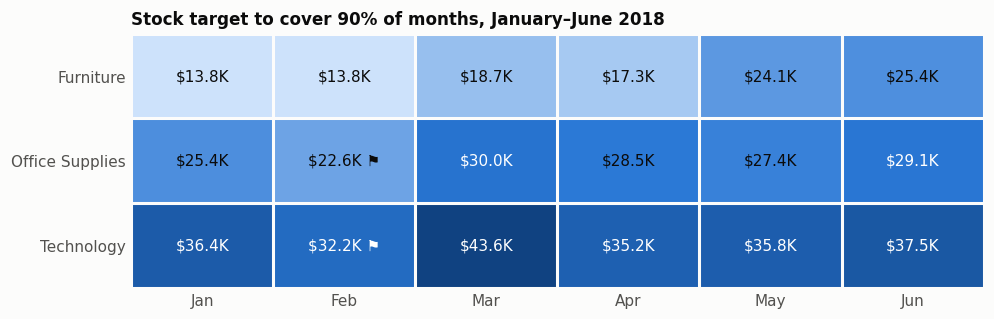

In [10]:
targets = plan.pivot(index="category", columns="month", values="stock_target").loc[CATEGORIES]
review = plan.pivot(index="category", columns="month", values="review").loc[CATEGORIES]
blues = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(10, 3))
image = ax.imshow(targets.values / 1000, cmap=blues, aspect="auto")
ax.set_xticks(range(targets.shape[1]), [f"{m:%b}" for m in targets.columns])
ax.set_yticks(range(len(CATEGORIES)), CATEGORIES)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.set_xticks(np.arange(-0.5, targets.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, len(CATEGORIES)), minor=True)
ax.grid(which="minor", color=plt.rcParams["figure.facecolor"], linewidth=2)
ax.tick_params(which="minor", length=0)

threshold = (targets.values.max() + targets.values.min()) / 2 / 1000
for row in range(targets.shape[0]):
    for col in range(targets.shape[1]):
        value = targets.iat[row, col] / 1000
        label = f"${value:,.1f}K" + (" ⚑" if review.iat[row, col] else "")
        ax.text(col, row, label, ha="center", va="center", fontsize=10,
                color="white" if value > threshold else INK)

ax.set_title(f"Stock target to cover {SERVICE_LEVEL:.0%} of months, January–June 2018")
fig.savefig(FIGURES_DIR / "09_stock_targets_2018H1.png")
plt.show()

### 5.2 — Where the Extra Stock Goes

In [11]:
summary = pd.DataFrame({
    "H1 stock target": targets.sum(axis=1),
    "H1 forecast": means[CATEGORIES].sum(),
    "H1 safety stock": plan.groupby("category")["safety_stock"].sum(),
    "peak month": targets.idxmax(axis=1).dt.strftime("%b"),
    "lowest month": targets.idxmin(axis=1).dt.strftime("%b"),
    "months flagged": review.sum(axis=1),
}).loc[CATEGORIES]
summary["safety share"] = summary["H1 safety stock"] / summary["H1 stock target"]
summary["forecast vs H1 2017"] = h1.loc[CATEGORIES, "growth"]
summary.style.format({
    "H1 stock target": "${:,.0f}", "H1 forecast": "${:,.0f}", "H1 safety stock": "${:,.0f}",
    "safety share": "{:.0%}", "forecast vs H1 2017": "{:+.0%}",
})

,H1 stock target,H1 forecast,H1 safety stock,peak month,lowest month,months flagged,safety share,forecast vs H1 2017
Furniture,"$113,074","$84,114","$28,960",Jun,Jan,0,26%,+22%
Office Supplies,"$162,971","$123,166","$39,806",Mar,Feb,1,24%,+38%
Technology,"$220,681","$141,783","$78,898",Mar,Feb,1,36%,+43%


---
## 6. RECOMMENDATIONS

### The forecast in one table

| Category | H1 2018 forecast | vs H1 2017 | H1 stock target (90%) | Of which safety stock | Peak month | Lowest month |
|---|---|---|---|---|---|---|
| Furniture | \\$84K | +22% | \\$113K | \\$29K (26%) | June | January |
| Office Supplies | \\$123K | +38% | \\$163K | \\$40K (24%) | March | February |
| Technology | \\$142K | +43% | \\$221K | \\$79K (36%) | March | February |
| **Total** | **\\$349K** | **+36%** | | | | |

### What to do

1. **Technology needs the most inventory, and the largest buffer.** It has the highest forecast and the most uncertain one: a standard error of about \\$10K a month, so \\$13K of safety stock every month, 36% of its stock target. Holding a third of the stock as buffer is expensive. Where possible, cover part of it with faster replenishment or supplier agreements instead of stock on the shelf.

2. **Build stock ahead of March for Office Supplies and Technology.** March is their H1 peak: stock targets of \\$30.0K (Office Supplies) and \\$43.6K (Technology), the highest of the half-year. Given supplier lead times, the orders belong in January–February.

3. **Ramp Furniture up from April towards May–June,** where its stock target reaches \\$24–25K, against \\$14K in January–February. Do not go above the target. The business diagnostics showed that Furniture has the thinnest margin (1.4% in 2017) and turns loss-making with discounts above 20%. Excess Furniture stock usually gets cleared with discounts, so overstocking it costs more than for any other category.

4. **Keep January–February lean, and review February before ordering.** These are the post-holiday trough months. February is flagged for Office Supplies and Technology: the model forecasts \\$15.9K and \\$19.0K, against \\$9.9K and \\$7.2K for last year's February grown at 2017's pace. In the holdout the model made the same mistake: it forecast Technology's February 2017 at \\$19.7K, and actual sales were \\$6.0K. *Judgment call:* plan Technology's February closer to last year's level plus the safety stock (about \\$7K + \\$13K ≈ \\$20K), rather than the model's \\$32K target.

5. **Keep Office Supplies' safety stock even though the forecast already grows 38%.** In the holdout, SARIMA under-forecast Office Supplies by 13%. Its safety stock (24% of the target) is what covers that risk.

### How far to trust these numbers
- **The growth may be optimistic.** The H1 forecast grows +36% against +20% for all of 2017: the drift term carries forward the strong second half of 2017, and H1 2017 was comparatively weak. In the holdout, the same models were within −13% to +8% of actual sales per category for the year. Treat the forecast as the upper half of a plausible range, and review it against January–February 2018 actuals as they come in.
- **The plan is in sales dollars.** Turning it into units per product needs each category's product mix and prices.
- **The second half of 2018 is not covered.** September, November and December are the year's biggest months (1.6–2.1× an average month). Re-run the forecast mid-year, with the first half of 2018 included, to plan for that peak.